# Scaleable Processing Workflows

In this course, most of our work has used individual Jupyter Notebooks, working with a few files at a time. This is a perfectly valid way to explore data and to communicate results, and is part of the reason why Jupyter Notebooks have become so popular with the data sciences. However, at some point in your geospatial scientific computing journey, you'll probably need to apply the same analysis to hundreds or thousands of files: every scene in a Landsat archive, every day of a climate record, or every instance of a feature (city, glacier, lake...) in a region (or the world!).

Here, we discuss how we might transition towards workflows are useful for processing large quantities of data. The focus here is how to _structure_ your code/files so that your workflows remain clear and manageable, rather than on making your code run faster (but we'll touch on that briefly towards the end).

As example data, we will use a record of ERA5 daily mean temperature (in °C) and precipitation (in mm) for Bristol, from 1940 to 2025. The data can be found at the following link. Unzip it and place the `era5_bristol_record` directory in the same directory as this notebook:

 - [ERA5 record of daily temperature and precipitation in Bristol, 1940-2025](https://raw.githubusercontent.com/trchudley/geospatial-scientific-computing/main/week/10/era5_bristol_record.zip).

As a single file, this dataset is less than 1 MB. However, to simulate a large dataset, I have split the data into individual monthly csv files in the format `YYYY/MM/YYYY-MM.csv`, "YYYY" is the year and "MM" is the month (e.g. 2017-08 for August 2017). As a result, our data is split across across 86 year directories and 1,032 monthly sub-directories. It is worth saying that this is not the most efficient way to store _this particular_ dataset (it really should be one file!), but it provides an example of the very common situation where your data are split across many files.

You'll need `tqdm` installed in your `gsc` environment if it isn't already (e.g. `conda activate gsc` and then `conda install -c conda-forge tqdm`). We will also use `dask`, which should already be installed as a dependency of the packages we have been using, but if not it can be installed in the same way.

In [3]:
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from tqdm import tqdm
from pathlib import Path

## Making code scale

### Path Management

When working with a few files in a personal project, it doesn't matter where they exist or what they're called. When you have thousands, your directory structure and file names become the main way that you (and your code) are able to keep track and navigate your data. A bit of thought at the start of a project saves a lot of pain later on. Some general principles:

 - Keep raw data and outputs in separate directories. For instance, `data/raw`, `data/interim`, `data/processed`, and `outputs/figures`. This makes it obvious what each file represents, and what can safely be deleted.
 - Treat your raw data as read-only: never overwrite it! If you realised you made a mistake in your processing, you can go back to the original data and start again.
 - Build output paths so that they mirror your input path directory structure. If your input file is `data/raw/bristol-20240515-landsat9-scene.tif`, then a sensible output might be `data/ndvi/bristol-20240515-landsat9-ndvi.tif`. Using `pathlib`, we can generate these automatically, which we will see below.
 - Use relative paths, as we discussed in [week 9](../09/01-repo-design.md). A path like `C:/Users/myname/Documents/project/data/` only works on your computer, but we want our scripts to be able to run anywhere they are downloaded (so long as directories are set appropriately). It's even better to build paths relative to the script itself (`Path(__file__).parent`) rather than relative to wherever you happen to be running it from. 

#### Naming conventions

By being carefuly with how you name your files, you can help yourself and others in the future. File names are free metadata, telling you (and your code) what's in the file, without opening it. You've already seen this in the real world: Landsat product IDs, such as `LC08_L2SP_042034_20260609_20260613_02_T1`, tell a user plenty of useful information, such as the satellite, processing level, path/row, acquisition date, processing date, collection, and tier.

I have been using similar simple templates throughout this course: typically, something like `{datasource}_{region}_{YYYYMMDD}_{product}.tif`. A few rules of thumb:

 - Use [ISO 8601](https://en.wikipedia.org/wiki/ISO_8601)-style date formats (`YYYY-MM-DD` or `YYYYMMDD`). These sort alphabetically into chronological order, whereas something like `11-07-2020` does not. Also, using different formats (e.g. DD-MM-YYYY or MM-DD-YYYY) can cause confusion across people from different countries who structure dates differently. Beginning with a year is unambiguous!
 - Zero-pad numbers (`07` rather than `7`; or `tile_003` rather than `tile_3`) for the same reason: when sorting, they will appear in order.
 - Do not use spaces or unusual characters that might confuse your code. Stick to letters, numbers, hyphens (`-`) and underscores (`_`).

If we follow a convention like this, we can extract metadata from a file name by simply splitting it up using the Python string `split()` function on our split character:

In [2]:
example_path = Path("data/processed/landsat9_bristol_20260711_ndvi.tif")

# .stem gives us the file name without the directory or the suffix
print(example_path.stem)

datasource, region, date, product = example_path.stem.split("_")

print(f"Data source: {datasource}, Region: {region}, Date: {date}, Product: {product}")

landsat9_bristol_20260711_ndvi
Data source: landsat9, Region: bristol, Date: 20260711, Product: ndvi


#### Finding files with `pathlib`

We have already used `Path.glob()` to find files that match a certain character structure (in [week 7](../07/03-temporal-change.ipynb)). In our ERA5 dataset, each CSV file sits two directories deep (`YYYY/MM/YYYY-MM.csv`), so we can use wildcards for each level:

In [5]:
data_dir = Path("era5_bristol_record")

# Find all files that are two directories deep and end in .csv
filepaths = data_dir.glob("*/*/*.csv")
filepaths = sorted(filepaths)

print(f"Found {len(filepaths)} files. Showing first 5:")
for i in filepaths[:5]:
    print(i)

Found 1032 files. Showing first 5:
era5_bristol_record/1940/01/1940-01.csv
era5_bristol_record/1940/02/1940-02.csv
era5_bristol_record/1940/03/1940-03.csv
era5_bristol_record/1940/04/1940-04.csv
era5_bristol_record/1940/05/1940-05.csv


I've `sorted()` the results, as the order that `.glob()` returns files in is not guaranteed (it depends, among other things, on your operating system). It's good practice to always sort them. As an additional bonus, because our file names follow the naming conventions above, we know that sorting our files alphabetically also sorts them chronologically.

Finally, I've printed an output that confirms how many filepaths I've found and what they might be. Always check that you've actually found some files! If you get the pattern wrong, `.glob()` won't complain, it will just return an empty list, and a loop over an empty list will silently 'succeed' without doing anything. A easy way for a human to validate an output will save you plenty of time.

`Path` objects also make it easy to pull apart and rebuild file paths. This is how we'll build output paths that mirror our input paths:

In [5]:
fp = filepaths[0]

print("Full path:     ", fp)
print("File name:     ", fp.name)
print("Stem:          ", fp.stem)
print("Parent dir:    ", fp.parent)
print("Relative path: ", fp.relative_to(data_dir))

# Build an output path that mirrors the input structure, but with a different suffix
output_dir = Path("outputs/era5_bristol_plots")
out_path = output_dir / fp.relative_to(data_dir).with_suffix(".png")

print("Output path:   ", out_path)

Full path:      era5_bristol_record/1940/01/1940-01.csv
File name:      1940-01.csv
Stem:           1940-01
Parent dir:     era5_bristol_record/1940/01
Relative path:  1940/01/1940-01.csv
Output path:    outputs/era5_bristol_plots/1940/01/1940-01.png


#### Processing many files

Now we can navigate this complex directory structure of files, let's do something with them. We'll loop through every csv file and calculate the mean temperature and the total precipitation for each month so we can present monthly data. The loop will store the results in a list of dictionaries that we turn into a `DataFrame` at the end.

In [7]:
monthly_records = []

for fp in tqdm(filepaths):

    df = pd.read_csv(fp, parse_dates=["date"])

    monthly_records.append({
        "month": df["date"].iloc[0],  # first day of the month
        "mean_temperature_degC": df["temperature_2m_mean_degC"].mean(),
        "total_precipitation_mm": df["precipitation_sum_mm"].sum(),
    })

df_monthly = pd.DataFrame(monthly_records).set_index("month")

df_monthly

100%|██████████| 1032/1032 [00:00<00:00, 1232.37it/s]


,mean_temperature_degC,total_precipitation_mm
month,,
1940-01-01,-1.103226,70.6
1940-02-01,4.737931,50.2
1940-03-01,6.277419,69.9
1940-04-01,9.736667,66.2
1940-05-01,13.935484,14.7
...,...,...
2025-08-01,18.070968,48.0
2025-09-01,13.620000,94.4
2025-10-01,11.716129,79.8


You'll notice I wrapped `filepaths` in `tqdm()` in the loop line. `tqdm` is our new package for the day: it doesn't change what the loop does, but instead gives us a progress bar. This is reassuring when you're looping through thousands of files and want to know [whether to go and make a cup of tea](https://xkcd.com/303/).

Let's plot the result. I've also plotted a 10-year (120-month) rolling mean on top to try and identify any trends.

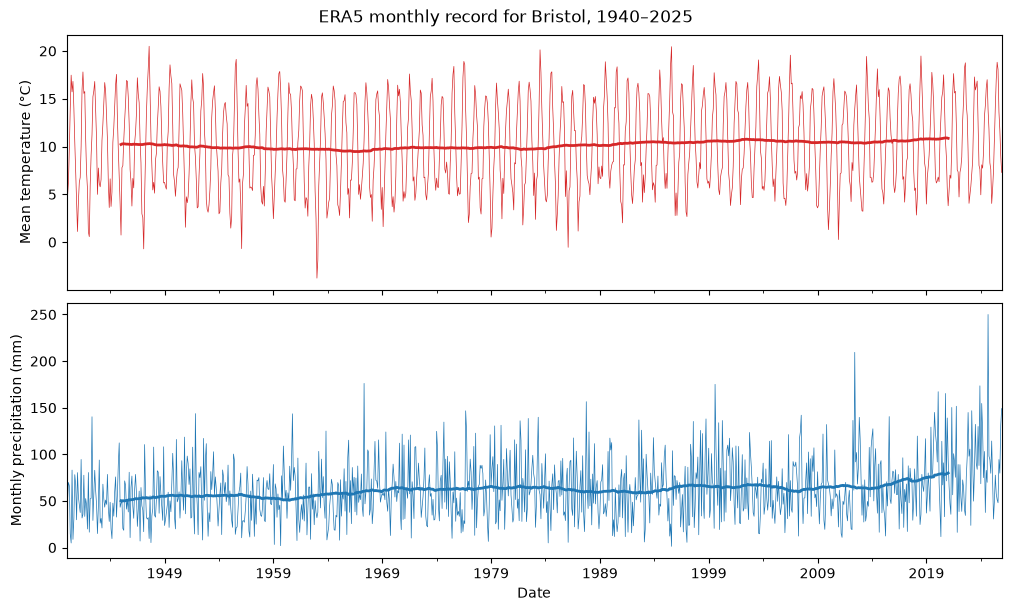

In [ ]:
fig, axes = plt.subplots(nrows=2, figsize=(10, 6), sharex=True, layout="constrained")

ax = axes[0]
df_monthly["mean_temperature_degC"].plot(ax=ax, color="tab:red", lw=0.5)
df_monthly["mean_temperature_degC"].rolling(120, center=True).mean().plot(ax=ax, color="tab:red", lw=2)
ax.set_ylabel("Mean temperature (°C)")

ax = axes[1]
df_monthly["total_precipitation_mm"].plot(ax=ax, color="tab:blue", lw=0.5)
df_monthly["total_precipitation_mm"].rolling(120, center=True).mean().plot(ax=ax, color="tab:blue", lw=2)
ax.set_ylabel("Monthly precipitation (mm)")
ax.set_xlabel("Date")

fig.suptitle("ERA5 monthly record for Bristol, 1940-2025")

plt.show()

### Modularising Code

So far, everything we have written have been inside individual notebooks (or the packages we import). As your projects grow, keeping all your code in notebooks starts to cause problems:

 - Notebooks are great for exploration and communication, but less good for code you want to reuse. If you want the same function in five different notebooks, you end up copying and pasting it five times. Then, when you find a bug, you have to fix it five times as well!
 - You can't easily `import` notebook functions into another notebook or script.
 - Notebook cells can be run out of order, or deleted after they were run, so the variables in memory don't necessarily match the code you can see.
 - Behind the scenes, notebook files are complex JSON documents full of different outputs (such as images) and metadata, which makes their `git` diffs very hard to read and track.

We will often choose to move "reusable" code (i.e. functions) into plain Python `.py` files, known as modules, and then `import` those functions into your notebooks or scripts. This replicates what you might see with `numpy` or `pandas`. Your notebook are places where you can call functions and look at the results, while the underlying "logic" (in-depth functions, etc.) lives in `.py` files where it can be reused and version controlled.

Let's try this. We'll create a new file called `plotting.py` in the same directory as this notebook, containing a function called `plot_graph()`. This function will plot our CSV files if we give it the appropriate `pandas` dataframe. We also define a `write_to_file` argument: if `write_to_file` is `None`, the plot will just be shown in the notebook; if it is a file path, the plot will be saved to that file instead, with the `fig` and `ax` objects, so that we can make further changes to the plot afterwards if we want to.

Normally, you would create this file in Jupyter Lab by going to **File** > **New** > **Python File** (or in any text editor), pasting the code below, and saving it as `plotting.py`. So that this notebook can run from top to bottom, I have included a `%%writefile` 'magic' command at the top of the cell, which instructs Jupyter to write the contents of the cell to a file.


In [11]:
%%writefile plotting.py
"""
plotting.py

Plotting functions for the daily ERA5 Bristol temperature and precipitation record.
"""

import matplotlib.pyplot as plt


def plot_graph(df, write_to_file=None):
    """
    Plot daily mean temperature (line) and precipitation (bars) from an ERA5 dataframe.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataframe containing the columns 'date', 'temperature_2m_mean_degC',
        and 'precipitation_sum_mm'.
    write_to_file : str or pathlib.Path, optional
        If None (default), the plot is displayed as normal. If a file path is
        given, the plot is saved to that file and the figure is closed.

    Returns
    -------
    fig : matplotlib.figure.Figure
    ax : matplotlib.axes.Axes
        The temperature axes.
    """

    fig, ax = plt.subplots(figsize=(8, 4))

    # Plot precipitation as bars on a second y-axis that shares the same x-axis
    ax_precip = ax.twinx()
    ax_precip.bar(df["date"], df["precipitation_sum_mm"], color="tab:blue", alpha=0.5)
    ax_precip.set_ylabel("Precipitation (mm)", color="tab:blue")
    ax_precip.set_ylim(0, None)

    # Plot temperature as a line, and make sure it is drawn on top of the bars
    ax.plot(df["date"], df["temperature_2m_mean_degC"], color="tab:red", marker=".")
    ax.set_ylabel("Mean temperature (°C)", color="tab:red")
    ax.set_zorder(ax_precip.get_zorder() + 1)  # "z order" controls which layer is drawn on top
    ax.patch.set_visible(False)

    start = df["date"].min().strftime("%Y-%m-%d")
    end = df["date"].max().strftime("%Y-%m-%d")
    ax.set_title(f"Bristol ERA5 daily record: {start} to {end}")

    fig.autofmt_xdate()

    # Either save and close the figure, or leave it open to be displayed
    if write_to_file is not None:
        fig.savefig(write_to_file, dpi=100, bbox_inches="tight")
        plt.close(fig)

    return fig, ax

Overwriting plotting.py


Before we import this function, there is one quirk of Jupyter worth knowing about. Python only reads a module the first time it is imported: if you then edit `plotting.py` and re-run your `import` cell, nothing will change, which can be very confusing! The `autoreload` extension fixes this by automatically re-importing modules whenever they change. It's worth putting these two lines at the top of any notebook where you are importing your own modules:

In [12]:
%load_ext autoreload
%autoreload 2

from plotting import plot_graph

Now we can use `plot_graph()` exactly like any other function. Let's plot July 2020:

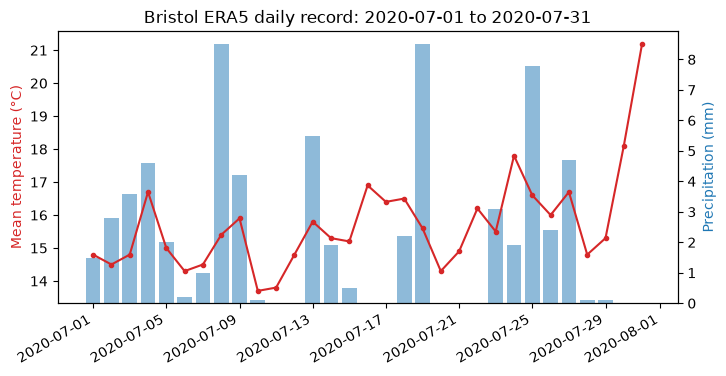

In [10]:
fp = data_dir / "2020" / "07" / "2020-07.csv"

df = pd.read_csv(fp, parse_dates=["date"])

fig, ax = plot_graph(df)

Because the function returns `fig` and `ax`, we can still make changes afterwards. For instance, adding a horizontal line at the monthly mean temperature:

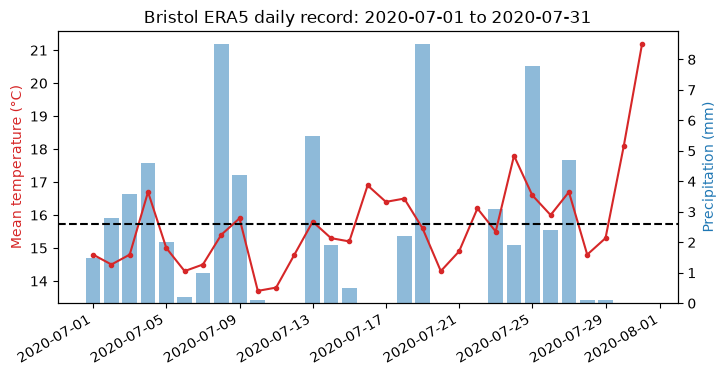

In [11]:
fig, ax = plot_graph(df)

ax.axhline(df["temperature_2m_mean_degC"].mean(), color="k", ls="--")

plt.show()

### Batch processing code

Now we have a reusable function, we want to apply it to every file. We could do this with a loop in this notebook. However, when processing a large amount of data, it's normal to move the large processing chains out of notebook-style environments and into a Python script (a `.py` file). A script will runs from top to bottom when you call it from the terminal (e.g. `python plot_graphs.py`) - just make sure you have your appropriate environment loaded. This has a few advantages:

 - Scripts can run unattended. You can start a script in your terminal, leave it running overnight, and come back to it in the morning. You don't need to keep a browser tab open, or keep on running individual ceels of a notebook.
 - Scripts run from top to bottom, so there's no mix-ups going to happen from cells being run out of order.
 - Like modules, scripts are plain text files, so they play nicely with `git`.
 - If you ever move your work to a high performance computing (HPC) cluster (see the end of this notebook), there typically isn't a Jupyter interface at all.

Let's create a script called `plot_graphs.py` which plots graphs for every csv file. Again, I'll use `%%writefile` here, but you can create it yourself in Jupyter Lab, text editor, or a preferred IDE if you have one. Read through it, and then we'll discuss the main features below.

In [ ]:
%%writefile plot_graphs.py
"""
plot_graphs.py

Plot a daily temperature/precipitation graph for every monthly ERA5 CSV file in
INPUT_DIR, saving the plots to OUTPUT_DIR using the same directory structure.

Run from the terminal using:

    python plot_graphs.py
"""

from pathlib import Path

import pandas as pd
from tqdm import tqdm

from plotting import plot_graph

# ---------------------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------------------

# Paths are built relative to the location of this script, rather than
# wherever the script happens to be run from
SCRIPT_DIR = Path(__file__).parent

INPUT_DIR = SCRIPT_DIR / "era5_bristol_record"
OUTPUT_DIR = SCRIPT_DIR / "outputs" / "era5_bristol_plots"

# If False, files that have already been processed will be skipped
OVERWRITE = False

# Note that writing variables in block caps is a common convention for 
# constants (i.e. variables that are not meant to be changed after they are 
# defined), but it is not enforced by Python.


# ---------------------------------------------------------------------------
# Functions
# ---------------------------------------------------------------------------

def process_file(in_path, out_path):
    """Read a single monthly ERA5 CSV file and save a plot of it."""
    df = pd.read_csv(in_path, parse_dates=["date"])
    plot_graph(df, write_to_file=out_path)


def main():

    filepaths = sorted(INPUT_DIR.glob("*/*/*.csv"))
    print(f"Found {len(filepaths)} files in {INPUT_DIR.name}")

    # Stop early if there is nothing to process
    if len(filepaths) == 0:
        raise FileNotFoundError(f"No CSV files found in {INPUT_DIR}")

    failed = []
    skipped = 0

    for in_path in tqdm(filepaths):

        # Build the output path so it mirrors the input path
        out_path = OUTPUT_DIR / in_path.relative_to(INPUT_DIR).with_suffix(".png")

        # Skip this file if it has already been processed
        if out_path.exists() and not OVERWRITE:
            skipped += 1
            continue

        # Create the output directory (and any parent directories) if needed
        out_path.parent.mkdir(parents=True, exist_ok=True)

        # If processing fails, record the file and the error, and move on
        try:
            process_file(in_path, out_path)
        except Exception as e:
            failed.append((in_path, e))

    print(f"Processed: {len(filepaths) - skipped - len(failed)}")
    print(f"Skipped (already exist): {skipped}")
    print(f"Failed: {len(failed)}")

    for path, error in failed:
        print(f"  {path}: {error}")


if __name__ == "__main__":
    main()

Overwriting plot_graphs.py


There are a few features here that are very typical of Python scripts.

First, the editable parameters are all defined as constants near the top of the file. We've done similar things in notebooks in this course. It means that if you want to run the same script on a different dataset, you only need to change one obvious place. By convention, constants like this are written in `UPPER_CASE`, which communicates that their values are not intended to be changed within the script - but this isn't enfirced by Python.

Second, the main body of code is wrapped up in a function called `main()`. There is a special `if` statement at the bottom of the file: `if __name__ == "__main__":`. This looks odd, but has a clear purpose. When Python runs a file directly (`python plot_graphs.py`), it sets a special hidden variable called `__name__` to `"__main__"`. When a file is imported (e.g. `from plot_graphs import process_file`), `__name__` is instead set to the name of the module. This means that `main()` only runs when we run the script, and not when we import it. So, if we later want to reuse the defined functions (in this case, `process_file()`) within a notebook, we can import it without accidentally kicking off the whole batch process!

Third, before processing each file, we check whether the output file already exists:

```python
if out_path.exists() and not OVERWRITE:
    continue
```

This is a small addition that makes a big difference. If your script crashes (or your laptop runs out of battery, or there's a powercut, or anything else that could go wrong) after processing 800 of 1,000 files, you can simply run it again, and it will pick up where it left off rather than starting from scratch. Setting `OVERWRITE` makes this options. We can set `OVERWRITE = True` and redo everything - for instance, if our processing has changed.

Finally, each file is processed within a `try`/`except` block. If something goes wrong with one file (for instance, a corrupt or empty file, which is surprisingly common in large datasets), we don't want the whole script to crash. However, we also don't want to silently ignore the problem! You will see examples online of code that looks like this:

```python
try:
    process_file(in_path, out_path)
except:
    pass
```

This is a bad habit: it will hide every possible error (including typos in your own code), and you'll never know which files failed. Instead, we catch the error with `except Exception as e:`, store the file path and the error message, and print a summary at the end so we can go back and investigate.

We can now run our script. You would normally do this from your terminal: navigate to the directory containing the script (using `cd`), make sure you have activated your environment (`conda activate gsc`), and run:

```
python plot_graphs.py
```

You can also run terminal commands from within Jupyter by prefixing them with `!`, which I'll do here:

In [13]:
!python plot_graphs.py

Found 1032 files in era5_bristol_record

Processed: 1032
Skipped (already exist): 0
Failed: 0


Let's check how many files we have created:

In [13]:
output_files = sorted(Path("outputs/era5_bristol_plots").rglob("*.png"))

print(f"{len(output_files)} plots created!")

1032 plots created!


Over 1,000 plots! And because our script skips existing files, if we run it again, it finishes almost instantly:

In [15]:
!python plot_graphs.py

Found 1032 files in era5_bristol_record

Processed: 0
Skipped (already exist): 1032
Failed: 0


To be clear, creating 1,000 plots isn't a particularly sensible or realistic goal (who is going to look at them all?). But the same structure applies to things you might well want to do, such as applying a processing step to 1,000 satellite images.

Think about how you might apply this to your own work. For instance, you might have a `data/raw` folder containing all the scenes you have downloaded. You could write a module containing a few functions (e.g. one to load a scene and apply a cloud mask, one to calculate a spectral index, one to clip it to your area of interest), and then a script that loops through the raw folder, applies those functions to each scene, and writes the results to a `data/processed` folder. The skeleton of that script might look something like this:

```python
from my_functions import load_scene, mask_clouds, calculate_ndwi, clip_to_aoi

INPUT_DIR = SCRIPT_DIR / "data" / "raw"
OUTPUT_DIR = SCRIPT_DIR / "data" / "processed"

def process_file(in_path, out_path):
    scene = load_scene(in_path)
    scene = mask_clouds(scene)
    ndwi = calculate_ndwi(scene)
    ndwi = clip_to_aoi(ndwi)
    ndwi.rio.to_raster(out_path)

def main():
    for in_path in tqdm(sorted(INPUT_DIR.glob("*.tif"))):
        out_path = OUTPUT_DIR / f"{in_path.stem}_ndwi.tif"
        ...
```

Your notebooks can then load the processed data to produce your figures and statistics.

## Making code more efficient

The aim of this notebook so far has been to show how to structure your code so that your analysis can scale to many files. It hasn't really been about how to make your code more efficient.

Below are some broad pointers for when your workflow does start to get slow (or runs out of memory). They're roughly in the order that you should consider them: there's no point setting up parallel processing on a supercomputer if the real problem is that you're loading ten times more data than you need!

<!-- ORIGINAL DRAFT TEXT:

This aim of this notebook was how to structure your code to scale your analysis: not necessarily on how you might make your code more efficient.

Some broad pointers here (include brief examples where appropriate), in order of what you should do.

-->

### Identify pinch points

Before trying to speed anything up, find out exactly where things are going wrong, so you're only spending effort on useful things. Jupyter has two useful 'magic' commands for this: `%time` (or `%%time` for a whole cell) runs code once and reports how long it took, and `%timeit` runs it many times and reports the average (useful for quick operations).

For instance, let's compare how long it takes to read one of our CSV files, versus how long it takes to make and save a plot from it:

In [16]:
fp = filepaths[0]

%timeit pd.read_csv(fp, parse_dates=["date"])

346 μs ± 29 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [17]:
%%time

df = pd.read_csv(fp, parse_dates=["date"])
fig, ax = plot_graph(df, write_to_file="outputs/test_plot.png")

CPU times: user 68.4 ms, sys: 8.61 ms, total: 77 ms
Wall time: 84.1 ms


Reading the data takes well under a millisecond, whereas making and saving the plot takes tens of milliseconds (~a hundred times longer). So our computer spend almost of its time plotting. If we wanted to speed up our script, there's no point worrying about how we read the files: we would need to focus on the plotting.

### Load only what is necessary (subsetting and `dask`)

As well as time, when working with very large files we keep an eye on the memory our scripts are using. If your Jupyter kernel crashes with no explanation, or your computer runs to a crawl, it's quite likely you're running out of memory. You could validate this by checking the size of an `xarray` object with `.nbytes`, and watch your overall memory use in Task Manager (Windows) or Activity Monitor (macOS).

#### Subsetting

The easiest way to fix this is to process less data. Subset your data by space, time, bands, and variables as early as possible, ideally before it is even loaded into memory. You've already done this when downloading data: in [week 5](../05/03-downloading-data.ipynb) we passed a `bbox` and a list of `bands` to `odc.stac.load()`, and in [week 8](../08/01-basic-gee.ipynb) we filtered Earth Engine collections by date and region before doing anything with them.

This is possible because these datasets are stored in cloud-native formats. As we discussed in the week 8 lecture, these are designed so that you can read just the part of a file that you need, without downloading the whole thing. Although this is framed as a way of working with files in the cloud, it's worth thinking about converting local large datasets to cloud-native formats (e.g.: tables to parquet, vectors to geoparquet, rasters to cloud-optimised geotiffs, and netcdfs to zarr). Subsetting can make them just as useful on your own hard drive as they are on the cloud.

For more information, the [Cloud-Native Geospatial Formats Guide](https://guide.cloudnativegeo.org/) is an excellent resource. 

#### Dask

(Here, we will also use the `era5_regional.nc` file from [week 4](../04/02-xarray.ipynb), so if you want to run these cells make sure that it is copied into this directory too.)

Sometimes, even after subsetting, your data won't fit in memory. This is where `dask` comes in. `dask` is a library for parallel and out-of-memory computing that integrates closely with `xarray`. It works by splitting arrays into smaller pieces called chunks, which can be loaded as needed. It also uses lazy evaluation: rather than calculating things immediately, it builds up a list of the operations you have asked for (a 'task graph'), and only actually runs them, chunk by chunk, when you ask for the result.

You've actually already used `dask` without realising it! When we downloaded data using `odc.stac.load()`, the data weren't loaded immediately: we had to call `.compute()` to actually download them. This is because `odc.stac.load()` returns `dask`-backed arrays.

To use `dask` with `xarray`, we just need to provide a `chunks` argument when we open a dataset. Let's load the UK ERA5 dataset we used in week 4.

How should we choose the size and shape of our chunks? A good rule of thumb is to chunk along the dimensions you are _not_ going to reduce over. Here, we're going to calculate the mean temperature through time for every pixel. If each chunk contains the full time series for a smaller spatial area, each chunk can calculate its own temporal mean independently. So, we'll split our data spatially, but keep the whole of the `valid_time` dimension in each chunk (`-1` means "don't split this dimension").


In [17]:
era5 = xr.open_dataset(
    "era5_regional.nc",
    chunks={"valid_time": -1, "latitude": 26, "longitude": 35}
    )

era5

/var/folders/ny/9_bn4x3x03jc3w6nqv0m4l7c0000gp/T/ipykernel_25195/3668404032.py:1: UserWarning: The specified chunks separate the stored chunks along dimension "latitude" starting at index 26. This could degrade performance. Instead, consider rechunking after loading.
  era5 = xr.open_dataset(
/var/folders/ny/9_bn4x3x03jc3w6nqv0m4l7c0000gp/T/ipykernel_25195/3668404032.py:1: UserWarning: The specified chunks separate the stored chunks along dimension "longitude" starting at index 35. This could degrade performance. Instead, consider rechunking after loading.
  era5 = xr.open_dataset(


<xarray.Dataset> Size: 14MB
Dimensions:     (valid_time: 120, latitude: 104, longitude: 139)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 960B 2016-01-01 ... 2025-12-01
    expver      (valid_time) <U4 2kB dask.array<chunksize=(120,), meta=np.ndarray>
  * latitude    (latitude) float64 832B 59.8 59.7 59.6 59.5 ... 49.7 49.6 49.5
  * longitude   (longitude) float64 1kB -10.9 -10.8 -10.7 -10.6 ... 2.7 2.8 2.9
    number      int64 8B ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 7MB dask.array<chunksize=(120, 26, 35), meta=np.ndarray>
    tp          (valid_time, latitude, longitude) float32 7MB dask.array<chunksize=(120, 26, 35), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-09-25T15:22 GRIB to CDM+CF via cfgrib-0.9.1...



The dataset looks much the same as before, but if we look at the underlying data of one of the variables, we can see it is now a `dask` array, split into a grid of chunks:

In [18]:
era5["t2m"].data

dask.array<open_dataset-t2m, shape=(120, 104, 139), dtype=float32, chunksize=(120, 26, 35), chunktype=numpy.ndarray>

This visualisation is very useful for checking that your chunks are a sensible shape and size. We have ended up with 16 chunks which are on average ~400kb each.

This isn't actually a practical exercise: as a (very) rough rule of thumb, aim for chunks of around 100 MB. If they are too small, `dask` spends more time organising the chunks than processing them. Is they are too large, and you risk running out of memory, which is what we were trying to avoid.

Now, let's calculate the mean temperature in °C. Notice that this cell runs instantly, and the result is still a `dask` array: nothing has actually been calculated yet!

In [21]:
t2m_mean_c = era5["t2m"].mean(dim="valid_time") - 273.15

t2m_mean_c

<xarray.DataArray 't2m' (latitude: 104, longitude: 139)> Size: 58kB
dask.array<sub, shape=(104, 139), dtype=float32, chunksize=(26, 35), chunktype=numpy.ndarray>
Coordinates:
  * latitude   (latitude) float64 832B 59.8 59.7 59.6 59.5 ... 49.7 49.6 49.5
  * longitude  (longitude) float64 1kB -10.9 -10.8 -10.7 -10.6 ... 2.7 2.8 2.9
    number     int64 8B ...
Attributes: (12/31)
    GRIB_paramId:                             167
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      14456
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_gridType:                            regular_ll
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            unknown
    GRIB_surface:                             0.0

The calculation only happens when we ask for the result, either by calling `.compute()`, or implicitly by doing something that needs the final result to be computed. This could include plotting the data, or saving it to a file (e.g. `.to_netcdf()` or `.rio.to_raster()`).

In [22]:
%%time

t2m_mean_c = t2m_mean_c.compute()

CPU times: user 108 ms, sys: 43.1 ms, total: 151 ms
Wall time: 719 ms


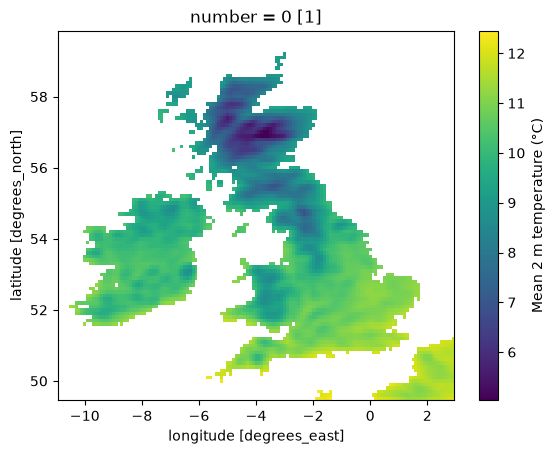

In [23]:
t2m_mean_c.plot(cbar_kwargs={"label": "Mean 2 m temperature (°C)"})

plt.show()

For comparison, let's do the same calculation without `dask`:

In [24]:
%%time

era5_numpy = xr.open_dataset("era5_regional.nc")

t2m_mean_c_numpy = (era5_numpy["t2m"].mean(dim="valid_time") - 273.15).compute()

CPU times: user 118 ms, sys: 24.7 ms, total: 143 ms
Wall time: 222 ms


For our example dataset here, you'll probably find that there's not much difference between the two. Indeed, depending on your computer, the `dask` version may even be slower. This is important: `dask` is not magic, and it has overheads. Our `era5_regional.nc` file is only a few MB, which fits in memory with no trouble at all, so there's no benefit from splitting it up. `dask` becomes useful when your data are too large to fit in memory (a rough rule of thumb is if your data are bigger than about a third of your RAM), or when you have lots of files to process at once. If your data fit comfortably in memory, you're usually better off without it.

The [`xarray` documentation on parallel computing with `dask`](https://docs.xarray.dev/en/stable/user-guide/dask.html) is a good place to start if you want to learn more.

### Vectorise

Back in [week 2](../02/01-numpy.ipynb), we saw that `numpy` operations on whole arrays are much faster than looping through values one at a time in Python. The same principle applies to `pandas` and `xarray`: where possible, avoid writing loops, and instead let the library do the work on the whole dataset at once (known as vectorisation).

Earlier, we looped through each file, calculated monthly statistics, and stored them in a list. An alternative is to read all the files into a single `DataFrame` with `pd.concat()`, and then use `pandas` time-series functionality (which we saw in [week 2](../02/03-pandas.ipynb)) to calculate the statistics in one go:

<!-- ORIGINAL DRAFT TEXT:

### Vectorise

Where appropriate, move from looping to vectorised approaches through xarray. We already discussed this all the way back in week 2. But not just numpy, also xarray datasets stacked through time.

Identify where looping still might be appropriate, though.

-->

In [24]:
%%time

# Read all files and combine them into one long DataFrame
df_all = pd.concat([pd.read_csv(fp, parse_dates=["date"]) for fp in filepaths])
df_all = df_all.set_index("date")

df_all

CPU times: user 451 ms, sys: 71.3 ms, total: 522 ms
Wall time: 796 ms


,temperature_2m_mean_degC,precipitation_sum_mm
date,,
1940-01-01,-0.2,NaN
1940-01-02,-1.1,0.0
1940-01-03,-1.2,0.0
1940-01-04,0.4,0.0
1940-01-05,0.3,0.0
...,...,...
2025-12-27,4.3,0.0
2025-12-28,5.5,0.0
2025-12-29,4.5,0.0


Once our data are in a single `DataFrame`, calculating monthly statistics is a single line using `.resample()`. And changing to annual statistics is trivial, whereas with our loop we'd have had to rewrite the whole thing:

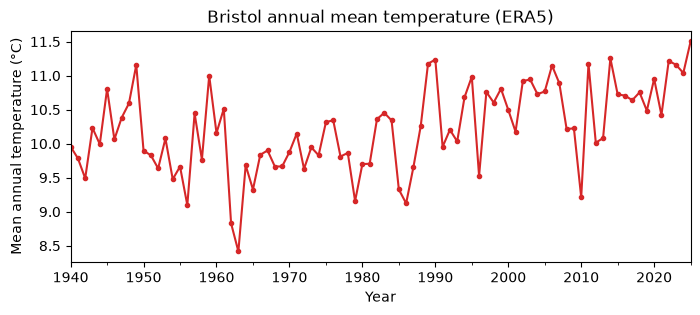

In [25]:
# 'MS' = month start
df_monthly_vectorised = df_all.resample("MS").agg({
    "temperature_2m_mean_degC": "mean",
    "precipitation_sum_mm": "sum"
    })

# 'YS' = year start
df_annual = df_all.resample("YS").agg({
    "temperature_2m_mean_degC": "mean",
    "precipitation_sum_mm": "sum"
    })

fig, ax = plt.subplots(figsize=(8, 3))
df_annual["temperature_2m_mean_degC"].plot(ax=ax, color="tab:red", marker=".")
ax.set_ylabel("Mean annual temperature (°C)")
ax.set_xlabel("Year")
ax.set_title("Bristol annual mean temperature (ERA5)")
plt.show()

The same principle applies to `xarray`. For instance, if we wanted the average temperature for each calendar month across our UK ERA5 dataset (i.e. a monthly climatology), we might be tempted to loop through the months 1 to 12, select the data for that month, and calculate a mean. Instead, `.groupby()` does this in a single line:

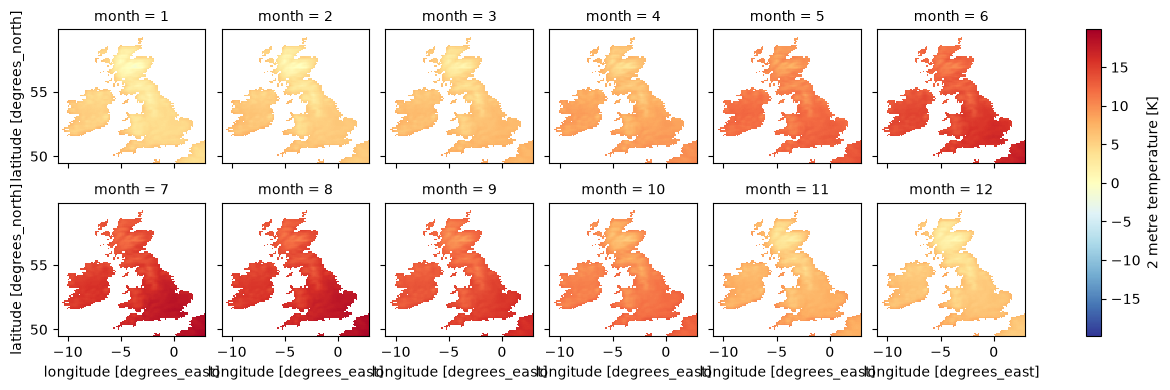

In [26]:
t2m_climatology = era5_numpy["t2m"].groupby("valid_time.month").mean() - 273.15

t2m_climatology.plot(col="month", col_wrap=6, cmap="RdYlBu_r", size=2)

plt.show()

This is also a lesson about how data are stored. Our ERA5 record split across 1,032 files is a deliberately bad example: once we've combined it into one `DataFrame`, it makes much more sense to save it as one file - indeed, this was how the file was originally downloaded.

That said, loops still have their place. Vectorisation requires all your data to be in memory at once, which won't always be possible. Looping over files (as in our batch script) is perfectly sensible when each file is large; when each file needs to be processed independently; or when the processing steps are too complex to express as a single operation. And sometimes a loop is simply easier to read and understand, which is worth a lot: the creator of Python, Guido van Rossum, has a principle that [code is read much more often than it is written](https://peps.python.org/pep-0008/). Therefore, there is a lot of value in creating "readable code" over clever code, even when the clever code is shorter to write or slghtly more efficient.

### Parallelise

By default, Python runs on a single core of your computer's processor. Most modern laptops have between 4 and 16 cores. Therefore, when you run a long loop, most of your computer is sitting idle!

Our batch script is a good example of an 'embarrassingly parallel' problem: each file is processed completely independently of the others, so there's no reason not to process several at the same time (i.e. "run them in parallel"). Python's built-in `concurrent.futures` module provides a relatively simple way of doing this. For instance, the loop in our `main()` function could be replaced by something like:

```python
from concurrent.futures import ProcessPoolExecutor

def main():
    ...
    # Create a list of input and output paths to process
    in_paths = [...]
    out_paths = [...]

    # Process files across 4 CPU cores at once
    with ProcessPoolExecutor(max_workers=4) as executor:
        list(tqdm(executor.map(process_file, in_paths, out_paths), total=len(in_paths)))
```

With 4 workers, this would process our files roughly (but not quite) four times faster. A few things to be aware of:

 - Each worker needs its own memory. If each file needs 4 GB of RAM to process, running 4 at once will need 16 GB.
 - Parallel processing in Jupyter can be temperamental, particularly on Windows and macOS. It generally works best in scripts, with the function being parallelised defined in an importable module (another reason to modularise your code!).
 - Error handling needs a bit more thought, as errors in one worker don't always show up where you'd expect.
 - If your bottleneck is downloading data or reading from a slow disk, rather than computation, more cores won't necessarily help.

Other popular options include [`joblib`](https://joblib.readthedocs.io/) (which is used by `scikit-learn` behind the scenes) and [`dask.delayed`](https://docs.dask.org/en/stable/delayed.html). 

For a more thorough introduction, Software Carpentries [Parallel Programming in Python](https://carpentries-incubator.github.io/lesson-parallel-python/) lesson is a good place to start.

### Move to bigger compute

Eventually, you might find that your laptop simply isn't up to the job. At this point (beyond getting a more powerful local computer), there are two main routes: high performance computing (HPC) clusters, and cloud computing.

An HPC cluster is essentially a large collection of powerful computers that many users share. You don't interact with it like your laptop: instead, you log in remotely through a terminal (via a process known as `ssh`), and submit 'jobs' (e.g. Python scripts) to a queue. A scheduler (at Bristol, and most other places, this is called SLURM) then runs your job when resources become available. 

The University of Bristol has its own HPC facilities, run by the Advanced Computing Research Centre (ACRC). You might not have access right now, but it is possible to [apply for HPC access for student projects](https://www.bristol.ac.uk/acrc/high-performance-computing/apply-for-hpc-access/teaching-and-student-projects/), usually with support from your dissertation supervisor. The ACRC also runs an [Introduction to HPC and SLURM course](https://www.acrc.bris.ac.uk/protected/hpc-docs/training/intro-to-hpc-slurm/index.html).

The alternative is cloud computing, which we discussed in week 8. Here, the processing happens on someone else's servers, ideally right next to where the data are stored: rather than downloading data to process it, we send our code to the data. You've already used Google Earth Engine in [week 8](../08/01-basic-gee.ipynb). Other options include commercial cloud providers (e.g. Amazon Web Services, Google Cloud, Microsoft Azure), many of which host large open geospatial datasets, although these typically cost money to use.

Either way, the good news is that if your code is already well structured into functions, modules, and scripts with relative paths, moving it to an HPC or cloud environment is much easier!

## Summary

In this notebook, we have looked at how to structure our code so that it can scale from a handful of files to thousands. We've seen how clear directory structures, consistent naming conventions, and `pathlib` can help us organise and find our data; how moving functions into modules makes them reusable; and how Python scripts can process large numbers of files robustly. We've also touched on some pointers for making things faster: find out what's slow, load only what you need, vectorise where possible, and then (if you really need to) parallelise or move to bigger computers.